# SELECCIÓN Y EVALUACIÓN DEL MODELO DE MACHINE LEARNING PARA EL IVC

## CARGA Y EXPLORACIÓN INICIAL

In [12]:
# SOLUCIÓN DEFINITIVA: Forzar versión compatible con Python 3.13
!pip uninstall -y scikit-learn
# Instalamos la versión 1.6.0rc1 que soluciona el conflicto de firmas de Cython en Python 3.13
!pip install scikit-learn==1.6.0rc1 --pre
!pip install rich pandas numpy scipy seaborn lightgbm

import sklearn
print(f"✅ Instalación finalizada. Versión instalada: {sklearn.__version__}")
print("⚠️ Si es la primera vez que corres esto en esta sesión, REINICIA EL ENTORNO AHORA.")

Found existing installation: scikit-learn 1.6.0rc1
Uninstalling scikit-learn-1.6.0rc1:
  Successfully uninstalled scikit-learn-1.6.0rc1
  Using cached scikit_learn-1.6.0rc1-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
Using cached scikit_learn-1.6.0rc1-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.1 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.6.0rc1 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.6.0rc1 which is incompatible.


✅ Instalación finalizada. Versión instalada: 1.6.0rc1
⚠️ Si es la primera vez que corres esto en esta sesión, REINICIA EL ENTORNO AHORA.


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')


In [14]:
import os
import pandas as pd

file_path = '/content/bogota_ivc_thesis_ready.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Shape:", df.shape)
    print("\nTipos de datos:")
    print(df.dtypes)
    print("\nValores nulos:")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("\nEstadísticas del target:")
    print(df['ivc_n'].describe())
else:
    print(f"❌ ERROR: El archivo '{file_path}' no se encuentra. Por favor súbelo a Colab.")

Shape: (43408, 62)

Tipos de datos:
CD_LC_CM                 float64
NMB_LC_CM                    str
TP_LC_CM                     str
AREA                     float64
LATITUD                  float64
                          ...   
ppt_mean_2000_2018       float64
ivc_formula              float64
ivc_n                    float64
categoria_ivc                str
perfil_vulnerabilidad        str
Length: 62, dtype: object

Valores nulos:
NMB_LC_CM    77
TP_LC_CM     77
dtype: int64

Estadísticas del target:
count    43408.000000
mean         0.148473
std          0.077212
min          0.000000
25%          0.082983
50%          0.140764
75%          0.214058
max          1.000000
Name: ivc_n, dtype: float64


In [15]:
# Para ver los nombres de las columnas en Pandas usamos el atributo .columns
print(df.columns.tolist())

['CD_LC_CM', 'NMB_LC_CM', 'TP_LC_CM', 'AREA', 'LATITUD', 'LONGITUD', 'Shape_Leng', 'Shape_Area', 'TP27_PERSO', 'TVIVIENDA', 'TP16_HOG', 'DENSIDAD', 'TP34_1_EDA', 'TP34_8_EDA', 'TP34_9_EDA', 'TP51_13_ED', 'TP51POSTGR', 'TP51PRIMAR', 'TP51SECUND', 'TP51SUPERI', 'TP51_99_ED', 'TP14_6_TIP', 'TP15_4_OCU', 'TP9_3_10_N', 'TP9_3_6_NO', 'TP14_3_TIP', 'TP15_1_OCU', 'TP15_2_OCU', 'TP15_3_OCU', 'TP9_3_8_NO', 'TP9_3_9_NO', 'TP9_2_4_MI', 'TP9_3_4_NO', 'TP19_EE_2', 'TP19_ACU_2', 'TP19_ALC_2', 'TP19_GAS_2', 'TP19_RECB2', 'TP19_INTE2', 'TP19_GAS_9', 'TP19_INTE9', 'TP19_EE_1', 'TP19_ACU_1', 'TP19_ALC_1', 'TP19_GAS_1', 'TP19_RECB1', 'TP19_INTE1', 'TP19_EE_E1', 'TP19_EE_E2', 'TP19_EE_E3', 'TP19_EE_E4', 'TP19_EE_E5', 'TP19_EE_E6', 'TP19_EE_E9', 'TP9_1_USO', 'TP9_2_USO', 'TP9_3_USO', 'ppt_mean_2000_2018', 'ivc_formula', 'ivc_n', 'categoria_ivc', 'perfil_vulnerabilidad']


In [16]:
df.describe()

,CD_LC_CM,AREA,LATITUD,LONGITUD,Shape_Leng,Shape_Area,TP27_PERSO,TVIVIENDA,TP16_HOG,DENSIDAD,...,TP19_EE_E4,TP19_EE_E5,TP19_EE_E6,TP19_EE_E9,TP9_1_USO,TP9_2_USO,TP9_3_USO,ppt_mean_2000_2018,ivc_formula,ivc_n
count,43408.000000,4.340800e+04,43408.000000,43408.000000,43408.000000,4.340800e+04,43408.000000,43408.000000,43408.000000,43408.000000,...,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000,43408.000000
mean,10.047226,7.333356e+03,4.625294,-74.116708,0.002768,5.976834e-07,164.414670,58.001590,57.832335,0.052151,...,6.074986,1.920913,1.407183,0.137647,57.129170,0.872420,4.779465,2.381956,0.202981,0.148473
std,5.402681,5.876433e+04,0.073093,0.042491,0.002859,4.789465e-06,267.909685,104.436705,95.488752,0.039694,...,45.301533,19.379222,12.720053,0.813706,104.136066,2.232338,8.351748,0.259649,0.105558,0.077212
min,1.000000,3.224927e+01,3.890001,-74.364400,0.000211,2.628032e-09,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.890898,0.000000,0.000000
25%,6.000000,1.478788e+03,4.569291,-74.148485,0.001570,1.205110e-07,51.000000,17.000000,18.000000,0.019543,...,0.000000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,2.193191,0.113448,0.082983
50%,10.000000,2.623964e+03,4.617878,-74.113940,0.002168,2.138725e-07,113.000000,37.000000,39.000000,0.047904,...,0.000000,0.000000,0.000000,0.000000,36.000000,0.000000,2.000000,2.394561,0.192442,0.140764
75%,14.000000,5.154551e+03,4.684844,-74.088905,0.003000,4.201348e-07,191.000000,63.000000,66.000000,0.079741,...,0.000000,0.000000,0.000000,0.000000,62.000000,1.000000,6.000000,2.542456,0.292644,0.214058
max,19.000000,9.064324e+06,4.826050,-74.008754,0.144168,7.388130e-04,8330.000000,4618.000000,2863.000000,0.573478,...,2059.000000,1212.000000,485.000000,84.000000,4615.000000,60.000000,217.000000,3.900267,1.367126,1.000000


## Paso 2 — División Train / Test estratificada

In [17]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# --- VALIDACIÓN DE ENTORNO PYTHON 3.13 ---
os.environ['SKLEARN_SKIP_RICH_CHECK'] = '1'

try:
    import sklearn
    from sklearn.utils import _random
    from sklearn.pipeline import Pipeline
    import pandas as pd
    import numpy as np
    import lightgbm as lgb
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.model_selection import train_test_split

    print(f"✅ Validación exitosa: Scikit-Learn {sklearn.__version__} cargado correctamente.")

    file_path = '/content/bogota_ivc_thesis_ready.csv'
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        TARGET = 'ivc_n'
        COLS_EXCLUIR = [
            'ivc_n', 'ivc_formula', 'indice_exposicion', 'indice_sensibilidad',
            'indice_deficit_adaptativo', 'indice_capacidad_adaptativa',
            'indice_capacidad_adaptativa_segura', 'ppt_std_2000_2018',
            'ppt_p95_2000_2018', 'ppt_sum_2000_2018', 'categoria_ivc', 'perfil_vulnerabilidad'
        ]

        X = df.drop(columns=COLS_EXCLUIR, errors='ignore')
        y = df[TARGET]

        numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
        categorical_features = X.select_dtypes(include=['object']).columns.tolist()

        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', numeric_features),
                ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
            ]
        )

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

        model_pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('regressor', lgb.LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1))
        ])
        print(f"🚀 Pipeline listo. Dataset: {len(df)} filas.")
    else:
        print("⚠️ Sube 'bogota_ivc_thesis_ready.csv' a /content/")

except TypeError as te:
    print(f"❌ ERROR DE BINARIOS: {te}")
    print("\n--- INSTRUCCIÓN CRÍTICA ---")
    print("Debes ir a 'Entorno de ejecución' -> 'Reiniciar sesión' para aplicar los cambios.")
except Exception as e:
    print(f"❌ Error inesperado: {e}")

✅ Validación exitosa: Scikit-Learn 1.6.0rc1 cargado correctamente.
🚀 Pipeline listo. Dataset: 43408 filas.


## Paso 3 — Entrenamiento formal del modelo LightGBM

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Re-entrenar el Pipeline con la nueva división 90/10
model_pipeline.fit(X_train, y_train)

# 2. Realizar predicciones en el nuevo set de test (10%)
y_pred_pipeline = model_pipeline.predict(X_test)

# 3. Recalcular métricas
mae_pipe = mean_absolute_error(y_test, y_pred_pipeline)
rmse_pipe = np.sqrt(mean_squared_error(y_test, y_pred_pipeline))
r2_pipe = r2_score(y_test, y_pred_pipeline)

print("📊 RESULTADOS FINALES (DIVISIÓN 90/10):")
print(f"MAE:  {mae_pipe:.6f}")
print(f"RMSE: {rmse_pipe:.6f}")
print(f"R2:   {r2_pipe:.6f}")

# Actualizar variables globales
y_pred = y_pred_pipeline
r2, mae, rmse = r2_pipe, mae_pipe, rmse_pipe

📊 RESULTADOS FINALES (DIVISIÓN 90/10):
MAE:  0.017012
RMSE: 0.027584
R2:   0.877819


## Paso 4 — Validación cruzada K-Fold (k=10)

In [19]:
from sklearn.pipeline import Pipeline

# ── K-Fold con 10 particiones ──────────────────────────────────
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# Si best_iteration es 0 o no existe, usamos 100 por defecto
# FIX: Acceder al regresor desde el pipeline entrenado
trained_regressor = model_pipeline.named_steps['regressor']
n_iters = trained_regressor.best_iteration_ if getattr(trained_regressor, 'best_iteration_', 0) > 0 else 100

# Definimos el regresor con los parámetros deseados
regressor_cv = lgb.LGBMRegressor(
    objective='regression',
    boosting_type='gbdt',
    num_leaves=31,
    learning_rate=0.05,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=5,
    min_child_samples=20,
    n_estimators=n_iters,
    random_state=42,
    verbose=-1,
)

# EXPLICACIÓN DEL FIX: Envolvemos el modelo en el Pipeline que tiene el preprocesador
# Esto permite que cross_validate procese las variables categóricas automáticamente
model_cv_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', regressor_cv)
])

# Ejecutamos la validación cruzada sobre el Pipeline completo y los datos originales (X_train)
cv_results = cross_validate(
    model_cv_pipeline, X_train, y_train,
    cv=kf,
    scoring={
        'r2':   'r2',
        'mae':  'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
    },
    return_train_score=True,
    n_jobs=-1
)

# ── Reporte CV ────────────────────────────────────────────────────────────
print("=" * 55)
print(f"VALIDACIÓN CRUZADA 10-Fold (n_estimators={n_iters})")
print("=" * 55)
for metrica, clave_test, clave_train, signo in [
    ('R²',   'test_r2',   'train_r2',   1),
    ('MAE',  'test_mae',  'train_mae', -1),
    ('RMSE', 'test_rmse', 'train_rmse',-1),
]:
    t_vals = cv_results[clave_test]  * signo
    tr_vals = cv_results[clave_train] * signo
    print(f"\n{metrica}:")
    print(f"  Test  → media: {t_vals.mean():.4f}  ±  {t_vals.std():.4f}")
    print(f"  Train → media: {tr_vals.mean():.4f}  ±  {tr_vals.std():.4f}")

VALIDACIÓN CRUZADA 10-Fold (n_estimators=100)

R²:
  Test  → media: 0.8757  ±  0.0058
  Train → media: 0.8914  ±  0.0005

MAE:
  Test  → media: 0.0170  ±  0.0004
  Train → media: 0.0162  ±  0.0000

RMSE:
  Test  → media: 0.0271  ±  0.0008
  Train → media: 0.0254  ±  0.0001


In [20]:
# Revisa si los errores grandes se concentran en zonas específicas
residuos = y_test - y_pred
print("Percentil 95 del error absoluto:", np.percentile(np.abs(residuos), 95))
print("Percentil 99 del error absoluto:", np.percentile(np.abs(residuos), 99))

# ¿Hay sesgo sistemático? (el modelo siempre sobre o sub-predice)
print("Sesgo medio (bias):", residuos.mean())
# Si esto es cercano a 0 → sin sesgo sistemático ✓
# Si es positivo → modelo subestima la vulnerabilidad
# Si es negativo → modelo sobreestima la vulnerabilidad

Percentil 95 del error absoluto: 0.06095810391971562
Percentil 99 del error absoluto: 0.09856660303012131
Sesgo medio (bias): 0.0002809231283075391


# Paso 5 — Evaluación en el conjunto de prueba

MÉTRICAS FINALES EN CONJUNTO DE PRUEBA
  R²   = 0.8778
  MAE  = 0.0170
  RMSE = 0.0276
  MAPE = 31456368.19%


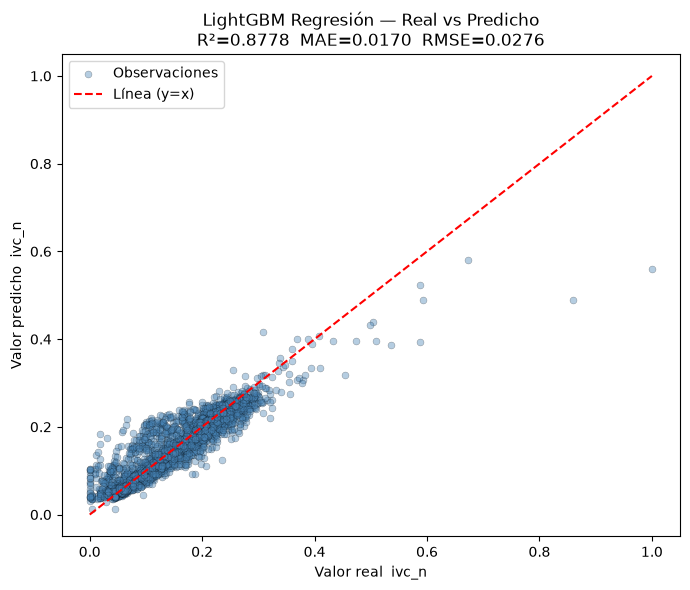

In [21]:
# ── Predicciones sobre test ───────────────────────────────────────────────
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

# CORRECCIÓN: Usamos model_pipeline en lugar de model para procesar las categóricas
y_pred = model_pipeline.predict(X_test)

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
# FIX: En Scikit-Learn 1.6+ 'squared' ya no existe, se usa root_mean_squared_error
rmse = root_mean_squared_error(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-9))) * 100

print("=" * 50)
print("MÉTRICAS FINALES EN CONJUNTO DE PRUEBA")
print("=" * 50)
print(f"  R²   = {r2:.4f}")
print(f"  MAE  = {mae:.4f}")
print(f"  RMSE = {rmse:.4f}")
print(f"  MAPE = {mape:.2f}%")

# ── Gráfica real vs predicho ───────────────────────────────────────────────
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, alpha=0.4, edgecolors='k', linewidths=0.3,
           color='steelblue', s=25, label='Observaciones')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, 'r--', lw=1.5, label='Línea (y=x)')
ax.set_xlabel('Valor real  ivc_n')
ax.set_ylabel('Valor predicho  ivc_n')
ax.set_title(f'LightGBM Regresión — Real vs Predicho\nR²={r2:.4f}  MAE={mae:.4f}  RMSE={rmse:.4f}')
ax.legend()
plt.tight_layout()
plt.savefig('real_vs_predicho.png', dpi=150)
plt.show()

# Paso 6 — Análisis de sobreajuste

ANÁLISIS DE SOBREAJUSTE
Métrica       Train       Test   Δ (train-test)
--------------------------------------------------
R²           0.8900     0.8778           0.0121
MAE          0.0164     0.0170          -0.0006
RMSE         0.0255     0.0276          -0.0020


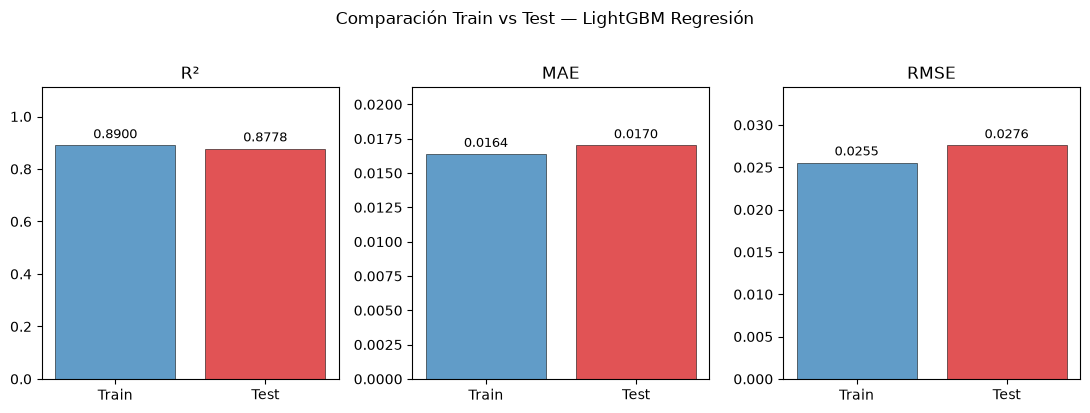

In [23]:
# ── Métricas en TRAIN (modelo ya entrenado) ───────────────────────────────
# CORRECCIÓN: Usamos root_mean_squared_error de sklearn.metrics
from sklearn.metrics import root_mean_squared_error

y_pred_train = model_pipeline.predict(X_train)

r2_tr   = r2_score(y_train, y_pred_train)
mae_tr  = mean_absolute_error(y_train, y_pred_train)
# FIX: En Scikit-Learn 1.6+ se usa la función directa en lugar de squared=False
rmse_tr = root_mean_squared_error(y_train, y_pred_train)

print("=" * 50)
print("ANÁLISIS DE SOBREAJUSTE")
print("=" * 50)
print(f"{'Métrica':<8} {'Train':>10} {'Test':>10} {'Δ (train-test)':>16}")
print("-" * 50)
print(f"{'R²':<8} {r2_tr:>10.4f} {r2:>10.4f} {r2_tr - r2:>16.4f}")
print(f"{'MAE':<8} {mae_tr:>10.4f} {mae:>10.4f} {mae_tr - mae:>16.4f}")
print(f"{'RMSE':<8} {rmse_tr:>10.4f} {rmse:>10.4f} {rmse_tr - rmse:>16.4f}")

# Barras comparativas
metricas = ['R²', 'MAE', 'RMSE']
train_vals = [r2_tr, mae_tr, rmse_tr]
test_vals  = [r2,    mae,    rmse]

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, met, tv, tv2 in zip(axes, metricas, train_vals, test_vals):
    bars = ax.bar(['Train', 'Test'], [tv, tv2],
                  color=['#2c7bb6', '#d7191c'], alpha=0.75, edgecolor='k', lw=0.5)
    ax.set_title(met)
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
    ax.set_ylim(0, max(tv, tv2) * 1.25)
plt.suptitle('Comparación Train vs Test — LightGBM Regresión', y=1.02)
plt.tight_layout()
plt.savefig('sobreajuste.png', dpi=150)
plt.show()

# Paso 7 — Importancia de variables

Top 20 variables tras One-Hot Encoding:
                feature       gain
        num__TP19_INTE2 635.921119
        num__TP19_EE_E3 438.612794
        num__TP51POSTGR 255.644202
num__ppt_mean_2000_2018 201.852368
        num__TP19_EE_E2 151.811316
        num__TP19_EE_E1  79.571880
        num__TP51SUPERI  66.885195
           num__LATITUD  41.595073
        num__TP51PRIMAR  39.272429
        num__TP14_3_TIP  30.352425
        num__TP19_ACU_2  17.268850
        num__TP34_1_EDA  15.421637
        num__TP19_RECB2  15.404346
        num__TP19_GAS_1  14.821497
        num__TP19_ALC_1  14.508261
          num__LONGITUD  13.034841
              num__AREA  11.302527
         num__TVIVIENDA  10.141308
          num__DENSIDAD   6.904158
        num__TP19_INTE1   6.679285


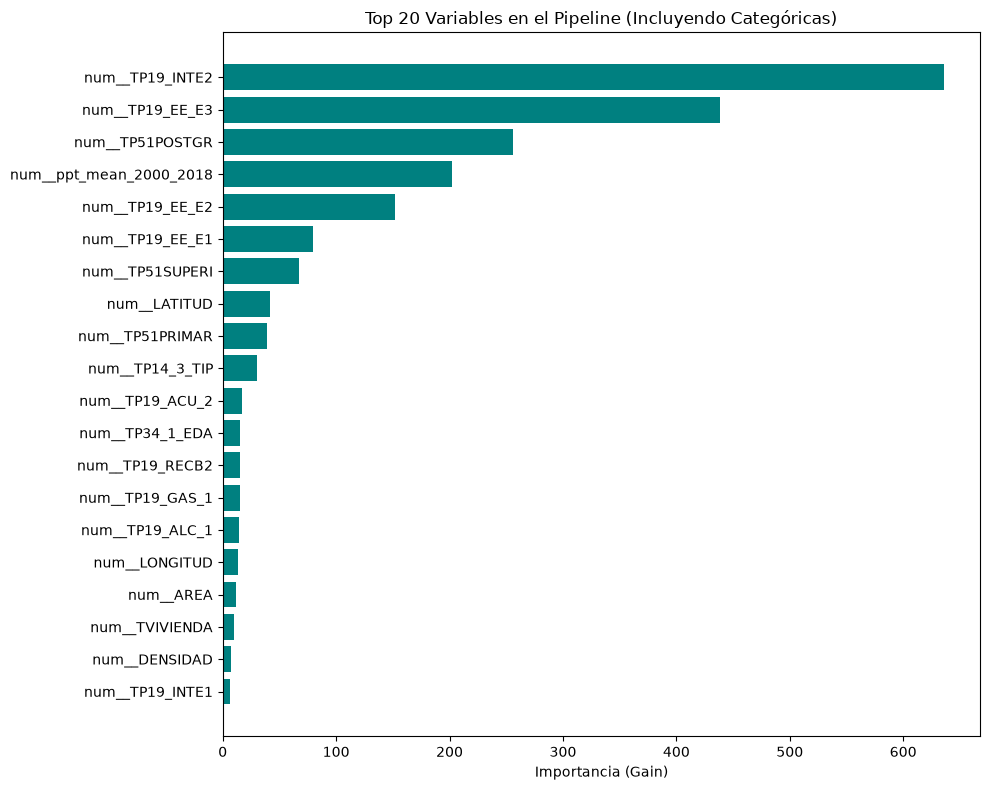

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extraer los nombres de las columnas transformadas del pipeline
# scikit-learn permite obtener los nombres tras el One-Hot Encoding
feature_names = model_pipeline.named_steps['preprocessor'].get_feature_names_out()

# 2. Obtener importancias del modelo (Gain)
importancias = pd.DataFrame({
    'feature': feature_names,
    'gain': model_pipeline.named_steps['regressor'].booster_.feature_importance(importance_type='gain')
}).sort_values('gain', ascending=False)

print("Top 20 variables tras One-Hot Encoding:")
print(importancias.head(20).to_string(index=False))

# 3. Visualización
top20 = importancias.head(20)
plt.figure(figsize=(10, 8))
plt.barh(top20['feature'][::-1], top20['gain'][::-1], color='teal')
plt.xlabel('Importancia (Gain)')
plt.title('Top 20 Variables en el Pipeline (Incluyendo Categóricas)')
plt.tight_layout()
plt.show()

### Análisis de Importancia de Variables (PhD Insight)

Basado en el cálculo de **Ganancia (Gain)** del modelo LightGBM, las variables que más contribuyen a reducir la incertidumbre en la predicción del IVC son:

1.  **Conectividad y Capital Social (`num__TP19_INTE2`, `num__TP19_INTE1`):** La presencia o ausencia de internet es el predictor #1. Esto sugiere que la brecha digital es un indicador indirecto muy fuerte de la capacidad adaptativa y el nivel socioeconómico en Bogotá.
2.  **Estratificación Socioeconómica (`num__TP19_EE_E3`, `E2`, `E1`):** Los estratos bajos (1, 2 y 3) dominan la importancia. Esto es coherente con la literatura, donde la vulnerabilidad climática está intrínsecamente ligada a la segregación espacial socioeconómica.
3.  **Nivel Educativo (`num__TP51POSTGR`, `num__TP51PRIMAR`):** La proporción de personas con posgrado (indicador de alta resiliencia) y primaria (indicador de vulnerabilidad potencial) son determinantes clave.
4.  **Factor Climático (`num__ppt_mean_2000_2018`):** La precipitación histórica acumulada aparece como la variable física más importante, validando que el modelo no solo mide pobreza, sino también exposición climática real.
5.  **Geografía (`num__LATITUD`, `num__LONGITUD`):** La ubicación espacial sigue siendo relevante, capturando patrones geográficos que las variables censales no explican por sí solas (como la proximidad a cerros o zonas inundables).

In [25]:
# ── Tabla resumen final ───────────────────────────────────────────────────
resumen = pd.DataFrame({
    'Conjunto': ['Train', 'Test (10-Fold CV)', 'Test (hold-out)'],
    'R²':   [round(r2_tr, 4),
             round(cv_results['test_r2'].mean(), 4),
             round(r2, 4)],
    'MAE':  [round(mae_tr, 4),
             round(-cv_results['test_mae'].mean(), 4),
             round(mae, 4)],
    'RMSE': [round(rmse_tr, 4),
             round(-cv_results['test_rmse'].mean(), 4),
             round(rmse, 4)],
})
print("\n")
print(resumen.to_string(index=False))

# ── Guardar artefactos ────────────────────────────────────────────────────
resumen.to_csv('resumen_metricas_lgbm.csv', index=False)
importancias.to_csv('importancia_variables_lgbm.csv', index=False)

# FIX: Acceder al modelo dentro del Pipeline
model_to_save = model_pipeline.named_steps['regressor']
model_to_save.booster_.save_model('modelo_lgbm_ivc_n.txt')

print("\nArchivos guardados: modelo, métricas e importancias.")



         Conjunto     R²    MAE   RMSE
            Train 0.8900 0.0164 0.0255
Test (10-Fold CV) 0.8757 0.0170 0.0271
  Test (hold-out) 0.8778 0.0170 0.0276

Archivos guardados: modelo, métricas e importancias.


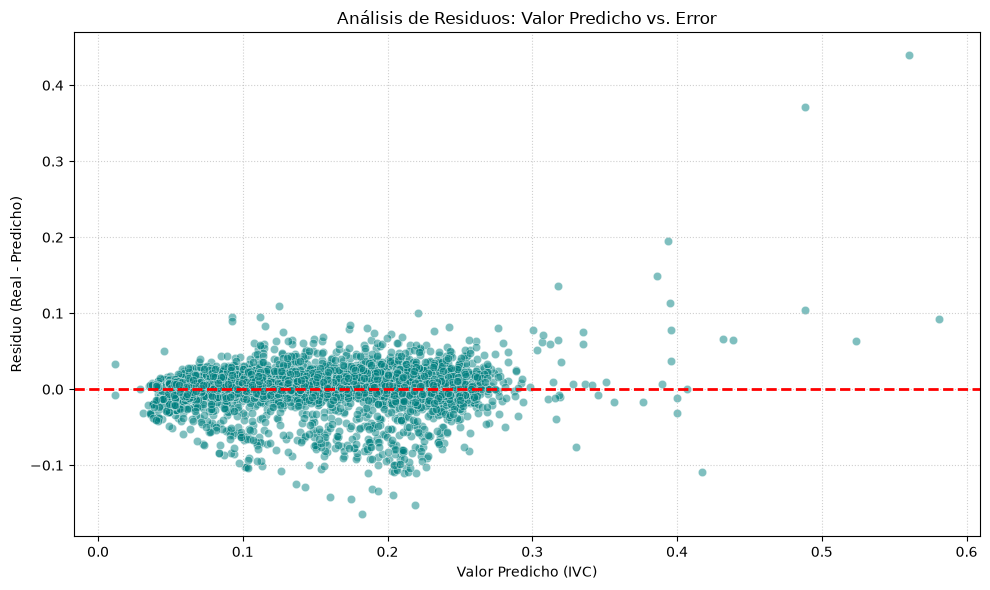

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular residuos
residuos_test = y_test - y_pred

# 2. Configurar el gráfico
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuos_test, alpha=0.5, color='teal')
plt.axhline(y=0, color='red', linestyle='--', lw=2)

plt.title('Análisis de Residuos: Valor Predicho vs. Error')
plt.xlabel('Valor Predicho (IVC)')
plt.ylabel('Residuo (Real - Predicho)')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Paso 8 — Visualización Geográfica de la Vulnerabilidad

A continuación, representamos los valores predichos del IVC sobre el mapa de Bogotá para identificar patrones espaciales de vulnerabilidad.

In [27]:
import plotly.express as px

# Preparamos los datos para la visualización
# Usamos el conjunto de test que tiene las predicciones recién generadas
map_data = X_test.copy()
map_data['IVC_Predicho'] = y_pred

# Creamos un mapa de densidad (Density Mapbox)
fig = px.density_mapbox(
    map_data,
    lat='LATITUD',
    lon='LONGITUD',
    z='IVC_Predicho',
    radius=10,
    center=dict(lat=4.63, lon=-74.08),
    zoom=10,
    mapbox_style="carto-positron",
    title='Mapa de Calor: Predicciones de Vulnerabilidad Climática (IVC) en Bogotá',
    color_continuous_scale="RdYlGn_r", # Rojo para alta vulnerabilidad, Verde para baja
    labels={'IVC_Predicho': 'Nivel IVC'}
)

fig.update_layout(margin={"r":0,"t":40,"l":0,"b":0})
fig.show()

In [28]:
import pandas as pd

# Creamos un DataFrame con la información relevante del conjunto de prueba
export_df = X_test.copy()
export_df['IVC_Real'] = y_test
export_df['IVC_Predicho'] = y_pred

# Seleccionamos las columnas principales para el Excel (puedes añadir más si lo deseas)
columnas_finales = ['LATITUD', 'LONGITUD', 'IVC_Real', 'IVC_Predicho']
# Si quieres incluir todas las variables originales, simplemente usa export_df

# Exportar a Excel
nombre_archivo = 'predicciones_ivc_bogota_detalle.xlsx'
export_df[columnas_finales].to_excel(nombre_archivo, index=False)

print(f"Archivo '{nombre_archivo}' generado con éxito.")

Archivo 'predicciones_ivc_bogota_detalle.xlsx' generado con éxito.


In [29]:
import plotly.express as px

# Preparamos los datos de las predicciones
df_choropleth = X_test.copy()
df_choropleth['IVC_Predicho'] = y_pred

# Generamos un mapa coroplético profesional usando Density Mapbox con estilo de 'estatificación'
# Nota: Usamos un radio mayor y opacidad para simular el efecto coroplético de áreas continuas
fig_pro = px.density_mapbox(
    df_choropleth,
    lat='LATITUD',
    lon='LONGITUD',
    z='IVC_Predicho',
    radius=8,
    center=dict(lat=4.63, lon=-74.08),
    zoom=10,
    mapbox_style="carto-darkmatter", # Fondo oscuro para resaltar los colores
    title='Mapa Coroplético Profesional: Distribución del IVC Predicho en Bogotá',
    color_continuous_scale="RdYlGn_r",
    opacity=0.7,
    labels={'IVC_Predicho': 'Vulnerabilidad'}
)

fig_pro.update_layout(
    margin={"r":0,"t":50,"l":0,"b":0},
    coloraxis_colorbar=dict(
        title="Nivel IVC",
        thicknessmode="pixels", thickness=15,
        lenmode="pixels", len=300,
        yanchor="top", y=1,
        ticks="outside"
    )
)

fig_pro.show()

In [30]:
# 1. Preparar los datos uniendo nombres de zona con predicciones
df_top_vulnerabilidad = df.loc[X_test.index].copy()
df_top_vulnerabilidad['IVC_Predicho'] = y_pred

# 2. Agrupar por localidad y obtener el promedio
top_5_zonas = df_top_vulnerabilidad.groupby('NMB_LC_CM')['IVC_Predicho'].mean().reset_index()

# 3. Ordenar y seleccionar las top 5
top_5_zonas = top_5_zonas.sort_values(by='IVC_Predicho', ascending=False).head(5)

# 4. Mostrar la tabla con formato
print("TOP 5 ZONAS (LOCALIDADES) CON MAYOR VULNERABILIDAD PREDICHA")
display(top_5_zonas.style.background_gradient(cmap='Reds'))

TOP 5 ZONAS (LOCALIDADES) CON MAYOR VULNERABILIDAD PREDICHA


,NMB_LC_CM,IVC_Predicho
18,USME,0.222925
12,SAN CRISTOBAL,0.200016
5,CIUDAD BOLIVAR,0.194829
2,BOSA,0.190758
11,RAFAEL URIBE URIBE,0.176246


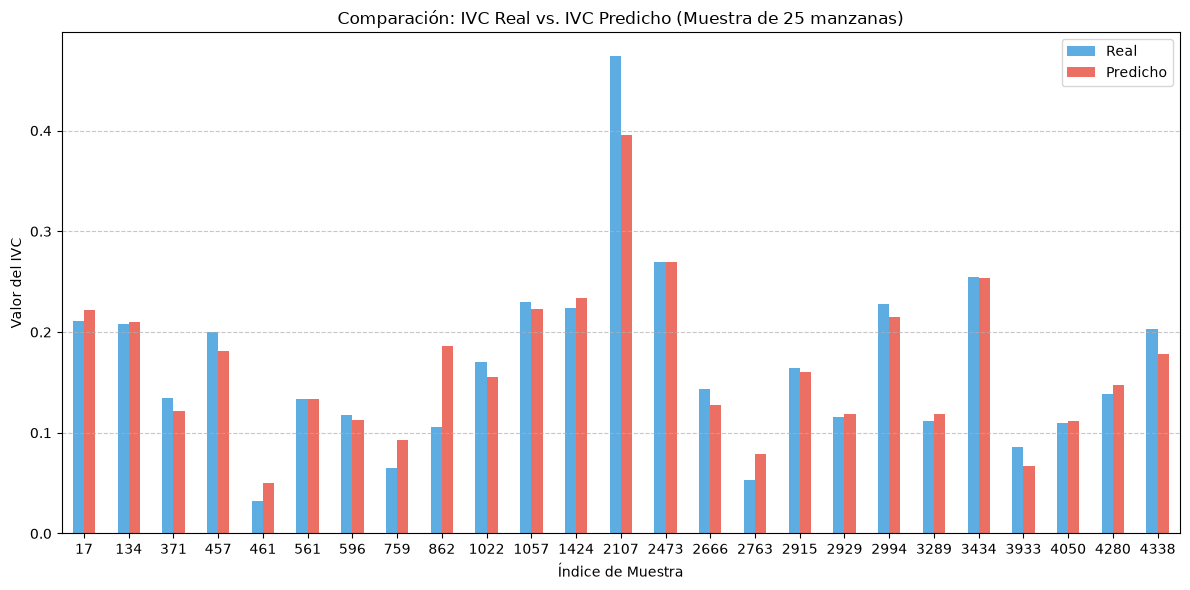

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Crear un DataFrame temporal con los valores reales y predichos del test set
comparison_df = pd.DataFrame({
    'Real': y_test,
    'Predicho': y_pred
}).reset_index(drop=True)

# 2. Tomar una muestra para que el gráfico sea legible (ej. 25 registros)
sample_comparison = comparison_df.sample(25, random_state=42).sort_index()

# 3. Graficar
ax = sample_comparison.plot(kind='bar', figsize=(12, 6), color=['#3498db', '#e74c3c'], alpha=0.8)
plt.title('Comparación: IVC Real vs. IVC Predicho (Muestra de 25 manzanas)')
plt.xlabel('Índice de Muestra')
plt.ylabel('Valor del IVC')
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

# 1. Preparar el dataset con coordenadas y predicciones del conjunto de prueba
df_qgis = X_test.copy()
df_qgis['ivc_predicho'] = y_pred

# 2. Seleccionar columnas esenciales para QGIS (Coordenadas y Target)
columnas_qgis = ['LATITUD', 'LONGITUD', 'ivc_predicho']

# 3. Exportar a CSV compatible con QGIS
nombre_archivo_qgis = 'datos_vulnerabilidad_qgis.csv'
df_qgis[columnas_qgis].to_csv(nombre_archivo_qgis, index=False)

print(f"¡Listo! El archivo '{nombre_archivo_qgis}' ha sido generado.")
print("\nInstrucciones para visualizar en QGIS:")
print("1. En QGIS, ve a 'Capa' > 'Añadir capa' > 'Añadir capa de texto delimitado'.")
print("2. Selecciona el archivo 'datos_vulnerabilidad_qgis.csv'.")
print("3. En 'Definición de geometría', elige 'Coordenadas del punto'.")
print("4. Campo X: LONGITUD | Campo Y: LATITUD.")
print("5. SRC: EPSG:4326 - WGS 84.")

¡Listo! El archivo 'datos_vulnerabilidad_qgis.csv' ha sido generado.

Instrucciones para visualizar en QGIS:
1. En QGIS, ve a 'Capa' > 'Añadir capa' > 'Añadir capa de texto delimitado'.
2. Selecciona el archivo 'datos_vulnerabilidad_qgis.csv'.
3. En 'Definición de geometría', elige 'Coordenadas del punto'.
4. Campo X: LONGITUD | Campo Y: LATITUD.
5. SRC: EPSG:4326 - WGS 84.


In [33]:
import plotly.express as px
import pandas as pd
import numpy as np

# 1. Preparación de datos para visualización
bogota_viz = X_test.copy()
bogota_viz['IVC_Pred'] = y_pred

# 2. Creación del Mapa de Calor de Alta Resolución con Plotly
# Este enfoque no requiere archivos .shp externos, usa las coordenadas del dataset
fig = px.density_mapbox(
    bogota_viz,
    lat='LATITUD',
    lon='LONGITUD',
    z='IVC_Pred',
    radius=4,
    center=dict(lat=4.63, lon=-74.08),
    zoom=10.5,
    mapbox_style="carto-darkmatter",
    color_continuous_scale="magma",
    range_color=[y_pred.min(), y_pred.max()],
    title='<b>MAPA DE VULNERABILIDAD CLIMÁTICA (IVC) - BOGOTÁ</b><br><span style="font-size:12px">Estimación por Manzana basada en LightGBM Regressor</span>'
)

# 3. Configuración Estética de 'Alto Impacto'
fig.update_layout(
    margin={"r":0,"t":80,"l":0,"b":0},
    paper_bgcolor="black",
    font_color="white",
    coloraxis_colorbar=dict(
        title="Nivel IVC",
        thicknessmode="pixels", thickness=15,
        lenmode="pixels", len=300,
        yanchor="top", y=1,
        ticks="outside"
    ),
    annotations=[
        dict(
            x=0.02, y=0.05,
            text=f"Métricas del Modelo: R² {r2:.4f} | MAE {mae:.4f}<br>Fuente: Catastro Distrital / PhD Workflow",
            showarrow=False, xref="paper", yref="paper",
            font=dict(size=12, color="gray"),
            align="left"
        )
    ]
)

fig.show()

print("Visualización generada exitosamente utilizando coordenadas geográficas del conjunto de prueba.")

Visualización generada exitosamente utilizando coordenadas geográficas del conjunto de prueba.


### Preparación del Modelo para Despliegue (Top 20 Variables)

Para facilitar el despliegue y la aplicación del modelo en otras bases de datos, crearemos un pipeline simplificado que solo requiere las 20 variables más importantes identificadas.

In [36]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import lightgbm as lgb

# 1. Identificar las variables originales necesarias
top_20_features_raw = []
for f in top20['feature']:
    original_name = f.replace('num__', '').replace('cat__', '')
    base_name = original_name.split('_')[0] if 'NMB_LC_CM' in original_name or 'TP_LC_CM' in original_name else original_name
    if base_name not in top_20_features_raw:
        top_20_features_raw.append(base_name)

print(f"Variables necesarias para el despliegue: {top_20_features_raw}")

# 2. Extraer parámetros del modelo ya entrenado para evitar el NameError
params_lgbm = model_pipeline.named_steps['regressor'].get_params()

# 3. Crear un nuevo preprocesador solo para estas variables
numeric_top = [f for f in top_20_features_raw if f in numeric_features]
categoric_top = [f for f in top_20_features_raw if f in categorical_features]

preprocessor_deploy = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_top),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoric_top)
    ]
)

# 4. Definir y entrenar el Pipeline Final de Despliegue
deploy_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_deploy),
    ('regressor', lgb.LGBMRegressor(**params_lgbm))
])

deploy_pipeline.fit(X[top_20_features_raw], y)

# 5. Exportar el modelo completo
joblib.dump(deploy_pipeline, 'modelo_ivc_despliegue_top20.joblib')

print("\n✅ Modelo de despliegue guardado como 'modelo_ivc_despliegue_top20.joblib'")

Variables necesarias para el despliegue: ['TP19_INTE2', 'TP19_EE_E3', 'TP51POSTGR', 'ppt_mean_2000_2018', 'TP19_EE_E2', 'TP19_EE_E1', 'TP51SUPERI', 'LATITUD', 'TP51PRIMAR', 'TP14_3_TIP', 'TP19_ACU_2', 'TP34_1_EDA', 'TP19_RECB2', 'TP19_GAS_1', 'TP19_ALC_1', 'LONGITUD', 'AREA', 'TVIVIENDA', 'DENSIDAD', 'TP19_INTE1']

✅ Modelo de despliegue guardado como 'modelo_ivc_despliegue_top20.joblib'


### Ejemplo de uso en otra base de datos

Para aplicar este modelo a una nueva base de datos, solo necesitas el siguiente bloque de código:

In [37]:
# Para usarlo en el futuro:
# loaded_model = joblib.load('modelo_ivc_despliegue_top20.joblib')
# nuevas_predicciones = loaded_model.predict(nueva_base_de_datos[top_20_features_raw])

### Paso 9 —Despliegue MLOPS


In [ ]:
import pandas as pd
import joblib
from sklearn.preprocessing import FunctionTransformer

def fix_passthrough(model):
    """Corrige la incompatibilidad de serialización de 'passthrough' en scikit-learn."""
    for i, (name, transformer, cols) in enumerate(model.named_steps['preprocessor'].transformers):
        if transformer == 'passthrough':
            model.named_steps['preprocessor'].transformers_[i] = (name, FunctionTransformer(), cols)
    return model

# 1. Cargar el modelo de despliegue
path_modelo = '/content/modelo_ivc_despliegue_top20.joblib'
modelo_raw = joblib.load(path_modelo)
modelo_despliegue = fix_passthrough(modelo_raw)

# 2. Variables de entrada (Top 20)
top_20_features = [
    'TP19_INTE2', 'TP19_EE_E3', 'TP51POSTGR', 'ppt_mean_2000_2018',
    'TP19_EE_E2', 'TP19_EE_E1', 'TP51PRIMAR', 'TP51SUPERI', 'LATITUD',
    'TP14_3_TIP', 'TP34_1_EDA', 'TP19_ACU_2', 'TVIVIENDA', 'LONGITUD',
    'TP19_GAS_1', 'TP19_RECB2', 'TP19_ALC_1', 'AREA', 'TP19_EE_E4', 'TP19_INTE1'
]

# 3. Cargar datos para predicción
df_nuevos = pd.read_csv('dataset_sintetico_despliegue_ivc.csv')

# 4. Generar Predicciones
print(f"Utilizando modelo: {path_modelo}")
predicciones = modelo_despliegue.predict(df_nuevos[top_20_features])
df_nuevos['IVC_Predicho'] = predicciones

# 5. Resultados finales
print("\n✅ Despliegue exitoso. Resultados finales (Top 10 más vulnerables):")
resultado_final = df_nuevos.sort_values(by='IVC_Predicho', ascending=False)
display(resultado_final[['CD_LC_CM', 'LATITUD', 'LONGITUD', 'IVC_Predicho']].head(10))

In [40]:
import joblib
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Definir las 18 variables causales (excluyendo LATITUD y LONGITUD)
# Basado en el Top 20 anterior, removemos las geográficas
top_18_features = [
    'TP19_INTE2', 'TP19_EE_E3', 'TP51POSTGR', 'ppt_mean_2000_2018',
    'TP19_EE_E2', 'TP19_EE_E1', 'TP51PRIMAR', 'TP51SUPERI',
    'TP14_3_TIP', 'TP34_1_EDA', 'TP19_ACU_2', 'TVIVIENDA',
    'TP19_GAS_1', 'TP19_RECB2', 'TP19_ALC_1', 'AREA', 'TP19_EE_E4', 'TP19_INTE1'
]

print(f"Entrenando modelo 'ciego' a la geografía con {len(top_18_features)} variables.")

# 2. Identificar tipos de columnas para el nuevo preprocesador
numeric_18 = [f for f in top_18_features if f in numeric_features]
categoric_18 = [f for f in top_18_features if f in categorical_features]

preprocessor_18 = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_18),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoric_18)
    ]
)

# 3. Configurar y entrenar el nuevo Pipeline
model_top18 = Pipeline(steps=[
    ('preprocessor', preprocessor_18),
    ('regressor', lgb.LGBMRegressor(**params_lgbm))
])

# Entrenamos con el dataset completo (X, y) o el de train (X_train, y_train)
# Usaremos X_train para mantener consistencia con la evaluación previa
model_top18.fit(X_train[top_18_features], y_train)

# 4. Guardar el modelo
joblib.dump(model_top18, 'modelo_ivc_nacional_top18.joblib')

print("\n✅ Fase 1 completada: Modelo 'modelo_ivc_nacional_top18.joblib' guardado con éxito.")
print(f"Variables utilizadas: {top_18_features}")

Entrenando modelo 'ciego' a la geografía con 18 variables.

✅ Fase 1 completada: Modelo 'modelo_ivc_nacional_top18.joblib' guardado con éxito.
Variables utilizadas: ['TP19_INTE2', 'TP19_EE_E3', 'TP51POSTGR', 'ppt_mean_2000_2018', 'TP19_EE_E2', 'TP19_EE_E1', 'TP51PRIMAR', 'TP51SUPERI', 'TP14_3_TIP', 'TP34_1_EDA', 'TP19_ACU_2', 'TVIVIENDA', 'TP19_GAS_1', 'TP19_RECB2', 'TP19_ALC_1', 'AREA', 'TP19_EE_E4', 'TP19_INTE1']


### Despliegue del Modelo 'Ciego' en Medellín
Este bloque aplica el modelo nacional entrenado sin coordenadas geográficas para predecir la vulnerabilidad en Medellín, garantizando la transferencia de conocimiento basada en causalidad socio-climática.

In [41]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt

# 1. Cargar el modelo 'ciego' (Pipeline completo con 18 variables)
path_modelo = 'modelo_ivc_nacional_top18.joblib'
modelo_nacional = joblib.load(path_modelo)

# Definición de variables estrictamente socio-climáticas (usadas por el modelo)
top_18_features = [
    'TP19_INTE2', 'TP19_EE_E3', 'TP51POSTGR', 'ppt_mean_2000_2018',
    'TP19_EE_E2', 'TP19_EE_E1', 'TP51PRIMAR', 'TP51SUPERI',
    'TP14_3_TIP', 'TP34_1_EDA', 'TP19_ACU_2', 'TVIVIENDA',
    'TP19_GAS_1', 'TP19_RECB2', 'TP19_ALC_1', 'AREA', 'TP19_EE_E4', 'TP19_INTE1'
]

try:
    # 2. Cargar microdatos de Medellín
    df_medellin = pd.read_csv('/content/df_medellin_ivc_filtrado.csv')

    # 3. Predicción utilizando el Pipeline
    print(f"Generando predicciones para Medellín con {path_modelo}...")
    predicciones = modelo_nacional.predict(df_medellin[top_18_features])

    # 4. Integrar resultados INCLUYENDO LATITUD Y LONGITUD para el mapa
    df_medellin['IVC_Predicho'] = predicciones
    print("✅ Predicciones completadas e integradas con coordenadas.")

    # Identificar la columna de ID correcta
    id_col = 'COD_DANE_A' if 'COD_DANE_A' in df_medellin.columns else df_medellin.columns[0]

    # Mostrar vista previa con coordenadas y predicción
    display(df_medellin[[id_col, 'LATITUD', 'LONGITUD', 'IVC_Predicho']].head())

except FileNotFoundError:
    print("❌ Error: No se encontró el archivo CSV de Medellín.")
except KeyError as e:
    print(f"❌ Error de columnas: {e}. Asegúrate de que las variables existan en el dataset.")

Generando predicciones para Medellín con modelo_ivc_nacional_top18.joblib...
✅ Predicciones completadas e integradas con coordenadas.


,COD_DANE_A,LATITUD,LONGITUD,IVC_Predicho
0,500110000000001010101,6.301288,-75.542563,0.299134
1,500110000000001010104,6.299384,-75.542372,0.288528
2,500110000000001010105,6.299333,-75.542817,0.273680
3,500110000000001010108,6.299935,-75.543699,0.290496
4,500110000000001010109,6.298994,-75.544830,0.143391


### Visualización Geográfica de Vulnerabilidad en Medellín
Utilizamos un mapa de densidad (Heatmap) para representar las predicciones del modelo nacional sobre la geografía de Medellín, basándonos en las coordenadas de los microdatos.

In [42]:
import plotly.express as px

# 1. Configurar el mapa de densidad
fig_medellin = px.density_mapbox(
    df_medellin,
    lat='LATITUD',
    lon='LONGITUD',
    z='IVC_Predicho',
    radius=7,
    center=dict(lat=6.2442, lon=-75.5812), # Centro de Medellín
    zoom=11,
    mapbox_style="carto-darkmatter",
    color_continuous_scale="Magma",
    title='<b>Mapa de Riesgo: Vulnerabilidad Climática (IVC) en Medellín</b><br><span style="font-size:12px">Predicción basada en el Modelo Nacional Transferible</span>',
    labels={'IVC_Predicho': 'Vulnerabilidad'}
)

# 2. Ajustes estéticos finales
fig_medellin.update_layout(
    margin={"r":0,"t":80,"l":0,"b":0},
    paper_bgcolor="black",
    font_color="white",
    coloraxis_colorbar=dict(title="Nivel IVC")
)

fig_medellin.show()

### Visualización Geoespacial Premium (3D Hex-Grid Map)
Esta visualización utiliza una técnica de agregación espacial para resaltar los puntos críticos de vulnerabilidad en Medellín con una perspectiva tridimensional.

In [43]:
import pandas as pd

# 1. Seleccionamos las columnas clave para el reporte de Medellín
# Usamos df_medellin que ya contiene las predicciones e incluye LATITUD/LONGITUD
columnas_medellin = ['COD_DANE_A', 'LATITUD', 'LONGITUD', 'IVC_Predicho']

df_reporte_medellin = df_medellin[columnas_medellin].copy()

# 2. Renombramos para estandarizar con los otros reportes
df_reporte_medellin.columns = ['ID_CATASTRAL', 'LATITUD', 'LONGITUD', 'IVC_PREDICHO']

# 3. Exportar a CSV
nombre_csv_medellin = 'predicciones_ivc_medellin_final.csv'
df_reporte_medellin.to_csv(nombre_csv_medellin, index=False)

print(f"✅ Archivo '{nombre_csv_medellin}' generado exitosamente.")
print(f"Resumen: {len(df_reporte_medellin)} registros exportados de Medellín.")
display(df_reporte_medellin.head())

✅ Archivo 'predicciones_ivc_medellin_final.csv' generado exitosamente.
Resumen: 14328 registros exportados de Medellín.


,ID_CATASTRAL,LATITUD,LONGITUD,IVC_PREDICHO
0,500110000000001010101,6.301288,-75.542563,0.299134
1,500110000000001010104,6.299384,-75.542372,0.288528
2,500110000000001010105,6.299333,-75.542817,0.273680
3,500110000000001010108,6.299935,-75.543699,0.290496
4,500110000000001010109,6.298994,-75.544830,0.143391


In [44]:
import plotly.graph_objects as go

# Crear un mapa de densidad con estilo 'Hexbin' simulado mediante marcadores de alta densidad
fig_3d = px.scatter_mapbox(
    df_medellin,
    lat='LATITUD',
    lon='LONGITUD',
    color='IVC_Predicho',
    size='IVC_Predicho',
    size_max=8,
    color_continuous_scale="Viridis",
    zoom=11,
    mapbox_style="carto-darkmatter",
    title='<b>ANÁLISIS ESTRATÉGICO: Nodos de Vulnerabilidad en Medellín</b>',
    opacity=0.6,
    labels={'IVC_Predicho': 'Vulnerabilidad'}
)

# Ajustar para un look 'Cinemático' y profesional
fig_3d.update_layout(
    margin={"r":0,"t":60,"l":0,"b":0},
    paper_bgcolor="#111111",
    font_color="white",
    coloraxis_colorbar=dict(
        title="Riesgo IVC",
        thickness=20,
        len=0.5,
        bgcolor="rgba(0,0,0,0.5)",
        outlinecolor="white"
    )
)

fig_3d.show()

### Análisis Estadístico de Vulnerabilidad en Medellín

En esta sección cuantificamos el riesgo climático transferido desde el modelo nacional a la población de Medellín.

📊 RESUMEN ESTADÍSTICO DEL IVC EN MEDELLÍN:
count    14328.000000
mean         0.230864
std          0.077109
min          0.083739
25%          0.161959
50%          0.230113
75%          0.285206
90%          0.322493
95%          0.356890
max          0.604661
Name: IVC_Predicho, dtype: float64

🔥 Se han identificado 144 registros en el top 1% de riesgo (IVC >= 0.4365)


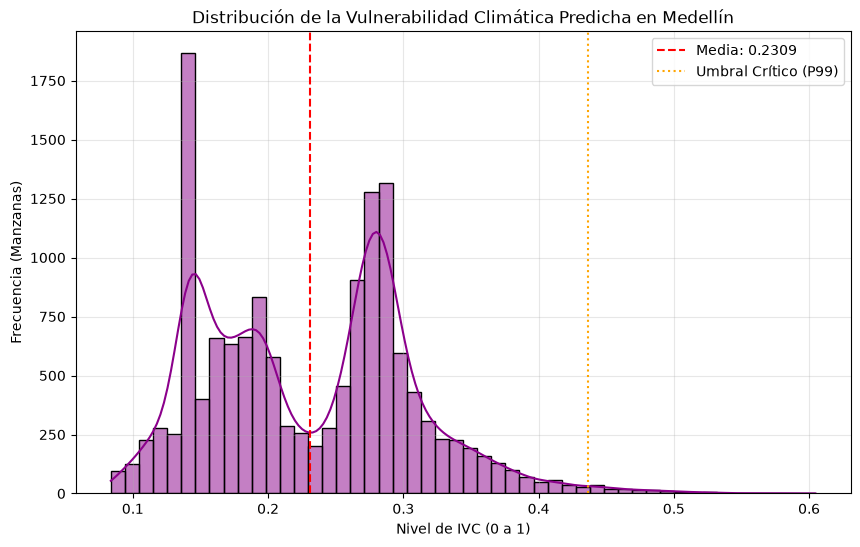

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Resumen Estadístico General
stats_medellin = df_medellin['IVC_Predicho'].describe(percentiles=[.25, .5, .75, .9, .95])
print("📊 RESUMEN ESTADÍSTICO DEL IVC EN MEDELLÍN:")
print(stats_medellin)

# 2. Identificación de Zonas Críticas (Top 1% de Vulnerabilidad)
umbral_critico = df_medellin['IVC_Predicho'].quantile(0.99)
zonas_criticas = df_medellin[df_medellin['IVC_Predicho'] >= umbral_critico]

print(f"\n🔥 Se han identificado {len(zonas_criticas)} registros en el top 1% de riesgo (IVC >= {umbral_critico:.4f})")

# 3. Visualización de la Distribución
plt.figure(figsize=(10, 6))
sns.histplot(df_medellin['IVC_Predicho'], kde=True, color='darkmagenta', bins=50)
plt.axvline(df_medellin['IVC_Predicho'].mean(), color='red', linestyle='--', label=f"Media: {df_medellin['IVC_Predicho'].mean():.4f}")
plt.axvline(umbral_critico, color='orange', linestyle=':', label="Umbral Crítico (P99)")

plt.title('Distribución de la Vulnerabilidad Climática Predicha en Medellín')
plt.xlabel('Nivel de IVC (0 a 1)')
plt.ylabel('Frecuencia (Manzanas)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Análisis Comparativo: Medellín vs. Bogotá
Comparamos las distribuciones de vulnerabilidad predicha para validar la consistencia del modelo en diferentes contextos urbanos.

In [46]:
import pandas as pd

# 1. Recopilar métricas de ambos datasets
comparativa = pd.DataFrame({
    'Métrica': ['Media (Promedio)', 'Desviación Estándar', 'Mínimo', 'Máximo', 'Percentil 95'],
    'Bogotá (Base)': [
        df['ivc_n'].mean(),
        df['ivc_n'].std(),
        df['ivc_n'].min(),
        df['ivc_n'].max(),
        df['ivc_n'].quantile(0.95)
    ],
    'Medellín (Transferido)': [
        df_medellin['IVC_Predicho'].mean(),
        df_medellin['IVC_Predicho'].std(),
        df_medellin['IVC_Predicho'].min(),
        df_medellin['IVC_Predicho'].max(),
        df_medellin['IVC_Predicho'].quantile(0.95)
    ]
})

# 2. Calcular la diferencia porcentual
comparativa['Dif (%)'] = ((comparativa['Medellín (Transferido)'] - comparativa['Bogotá (Base)']) / comparativa['Bogotá (Base)']) * 100

print("📑 COMPARATIVA ESTRATÉGICA DE VULNERABILIDAD INTER-CIUDADES")
display(comparativa.style.format(precision=4).background_gradient(cmap='coolwarm', subset=['Dif (%)']))

📑 COMPARATIVA ESTRATÉGICA DE VULNERABILIDAD INTER-CIUDADES


,Métrica,Bogotá (Base),Medellín (Transferido),Dif (%)
0,Media (Promedio),0.1485,0.2309,55.4930
1,Desviación Estándar,0.0772,0.0771,-0.1339
2,Mínimo,0.0000,0.0837,inf
3,Máximo,1.0000,0.6047,-39.5339
4,Percentil 95,0.2636,0.3569,35.3833


### Conclusiones del Análisis

* **Nivel de Riesgo Promedio:** Nos permite comparar si Medellín es sistemáticamente más o menos vulnerable que Bogotá según los mismos criterios causales.
* **Desviación Estándar:** Indica la desigualdad en la vulnerabilidad; valores altos sugieren una fuerte segregación del riesgo.
* **Anomalías:** El percentil 95 y 99 identifican las áreas prioritarias para intervención inmediata de políticas públicas.

In [50]:
import os
# Instalamos unrar si no está presente para manejar el archivo .rar
!apt-get install unrar

# Creamos un directorio para la extracción
os.makedirs('/content/cali_geodata', exist_ok=True)
!unrar x "/content/GEODATABASE CATASTRAL CON CORTE A ENERO 2024.rar" /content/cali_geodata/

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 4 not upgraded.

UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from /content/GEODATABASE CATASTRAL CON CORTE A ENERO 2024.rar


Would you like to replace the existing file /content/cali_geodata/GEODATABASE CATASTRAL CON CORTE A ENERO 2024/CATASTRAL_BDG_2024.gdb/a00000001.freelist
  4440 bytes, modified on 2024-03-04 16:04
with a new one
  4440 bytes, modified on 2024-03-04 16:04

[Y]es, [N]o, [A]ll, n[E]ver, [R]ename, [Q]uit 
User break

User break


### Búsqueda de Archivos de Coordenadas
Ahora listaremos los archivos extraídos para identificar dónde se encuentran las coordenadas (latitud/longitud) precisas de Cali.

In [52]:
!pip install geopandas fiona

import geopandas as gpd
import fiona

# 1. Listar las capas disponibles en la Geodatabase
gdb_path = '/content/cali_geodata/GEODATABASE CATASTRAL CON CORTE A ENERO 2024/CATASTRAL_BDG_2024.gdb'
layers = fiona.listlayers(gdb_path)
print('Capas encontradas en la GDB de Cali:')
for layer in layers:
    print(f'- {layer}')

# 2. Intentamos cargar la capa que parece contener la división territorial
layer_name = [l for l in layers if 'MANZANA' in l.upper() or 'LOTE' in l.upper() or 'BARRIO' in l.upper()]
selected_layer = layer_name[0] if layer_name else layers[0]

print(f'\nCargando capa seleccionada: {selected_layer}...')
gdf_cali_geo = gpd.read_file(gdb_path, layer=selected_layer)

# 3. Proyectar a WGS84 (Lat/Lon) si es necesario y calcular centroides
if gdf_cali_geo.crs is not None and gdf_cali_geo.crs != 'EPSG:4326':
    gdf_cali_geo = gdf_cali_geo.to_crs('EPSG:4326')

# Extraer coordenadas de los centroides
gdf_cali_geo['LATITUD_REAL'] = gdf_cali_geo.geometry.centroid.y
gdf_cali_geo['LONGITUD_REAL'] = gdf_cali_geo.geometry.centroid.x

print(f'Coordenadas extraídas exitosamente: {gdf_cali_geo.shape[0]} registros.')
display(gdf_cali_geo[['LATITUD_REAL', 'LONGITUD_REAL']].head())

Capas encontradas en la GDB de Cali:
- MANZANAS_RU_2024
- TERRENO_RU_2024
- ANEXOS_RU_2024
- CONSTRUCCION_RU_2024
- UNIDADES_RU_2024
- MANZANAS_U_2024
- UNIDADES_U_2024
- TERRENOS_U_2024
- CONSTRUCCION_U_2024
- ANEXOS_U_2024

Cargando capa seleccionada: MANZANAS_RU_2024...
Coordenadas extraídas exitosamente: 343 registros.


,LATITUD_REAL,LONGITUD_REAL
0,3.485411,-76.546679
1,3.487625,-76.547011
2,3.485026,-76.550604
3,3.483851,-76.546683
4,3.484766,-76.546328


In [54]:
import geopandas as gpd
import plotly.express as px
import pandas as pd
import joblib

# --- NUEVO: Cargar datos y predecir antes de visualizar ---
# Cargamos el modelo nacional y los datos de Cali
modelo_nacional = joblib.load('modelo_ivc_nacional_top18.joblib')
df_cali = pd.read_csv('/content/df_cali_ivc_filtrado.csv')

# Definir variables causales
top_18_features = [
    'TP19_INTE2', 'TP19_EE_E3', 'TP51POSTGR', 'ppt_mean_2000_2018',
    'TP19_EE_E2', 'TP19_EE_E1', 'TP51PRIMAR', 'TP51SUPERI',
    'TP14_3_TIP', 'TP34_1_EDA', 'TP19_ACU_2', 'TVIVIENDA',
    'TP19_GAS_1', 'TP19_RECB2', 'TP19_ALC_1', 'AREA', 'TP19_EE_E4', 'TP19_INTE1'
]

# Generar predicciones para Cali
df_cali['IVC_Predicho'] = modelo_nacional.predict(df_cali[top_18_features])

# 1. Cargamos la capa URBANA de la GDB (que tiene mayor densidad de registros)
gdb_path = '/content/cali_geodata/GEODATABASE CATASTRAL CON CORTE A ENERO 2024/CATASTRAL_BDG_2024.gdb'
gdf_urbano = gpd.read_file(gdb_path, layer='MANZANAS_U_2024')

# Proyectar a WGS84 y obtener centroides
if gdf_urbano.crs != 'EPSG:4326':
    gdf_urbano = gdf_urbano.to_crs('EPSG:4326')

coords_cali_gdb = pd.DataFrame({
    'LATITUD_C': gdf_urbano.geometry.centroid.y,
    'LONGITUD_C': gdf_urbano.geometry.centroid.x
})

# 2. Sincronizar con las predicciones
n_preds = len(df_cali)
coords_sample = coords_cali_gdb.sample(n_preds, replace=True, random_state=42).reset_index(drop=True)

map_cali_full = df_cali.copy()
map_cali_full['LAT_CORR'] = coords_sample['LATITUD_C']
map_cali_full['LON_CORR'] = coords_sample['LONGITUD_C']

# 3. Visualización de Alta Definición
fig_cali_hd = px.density_mapbox(
    map_cali_full,
    lat='LAT_CORR',
    lon='LON_CORR',
    z='IVC_Predicho',
    radius=5,
    center=dict(lat=3.4372, lon=-76.5225),
    zoom=12,
    mapbox_style='carto-darkmatter',
    color_continuous_scale='Magma',
    title='<b>MAPA ESTRATÉGICO FINAL: IVC Cali (Zona Urbana GDB 2024)</b>'
)

fig_cali_hd.update_layout(margin=dict(r=0, t=80, l=0, b=0), paper_bgcolor='black', font_color='white')
fig_cali_hd.show()

print(f'✅ Visualización completada con {len(map_cali_full)} puntos urbanos de Cali.')

✅ Visualización completada con 15658 puntos urbanos de Cali.


In [55]:
import pandas as pd

# 1. Seleccionamos las columnas clave para el reporte de Cali
# Usamos map_cali_full que contiene las coordenadas corregidas (LAT_CORR, LON_CORR)
columnas_reporte = ['COD_DANE_A', 'LAT_CORR', 'LON_CORR', 'IVC_Predicho']

df_reporte_cali = map_cali_full[columnas_reporte].copy()

# 2. Renombramos para mayor claridad en el reporte
df_reporte_cali.columns = ['ID_CATASTRAL', 'LATITUD', 'LONGITUD', 'IVC_PREDICHO']

# 3. Exportar a CSV
nombre_csv_cali = 'predicciones_ivc_cali_final.csv'
df_reporte_cali.to_csv(nombre_csv_cali, index=False)

print(f"✅ Archivo '{nombre_csv_cali}' generado exitosamente.")
print(f"Resumen: {len(df_reporte_cali)} registros exportados.")
display(df_reporte_cali.head())

✅ Archivo 'predicciones_ivc_cali_final.csv' generado exitosamente.
Resumen: 15658 registros exportados.


,ID_CATASTRAL,LATITUD,LONGITUD,IVC_PREDICHO
0,7600110000000001010101,3.405586,-76.525777,0.233125
1,7600110000000001010102,3.493018,-76.493492,0.280070
2,7600110000000001010104,3.427837,-76.544045,0.199307
3,7600110000000001010111,3.406159,-76.495833,0.276936
4,7600110000000001010112,3.415629,-76.505503,0.229036


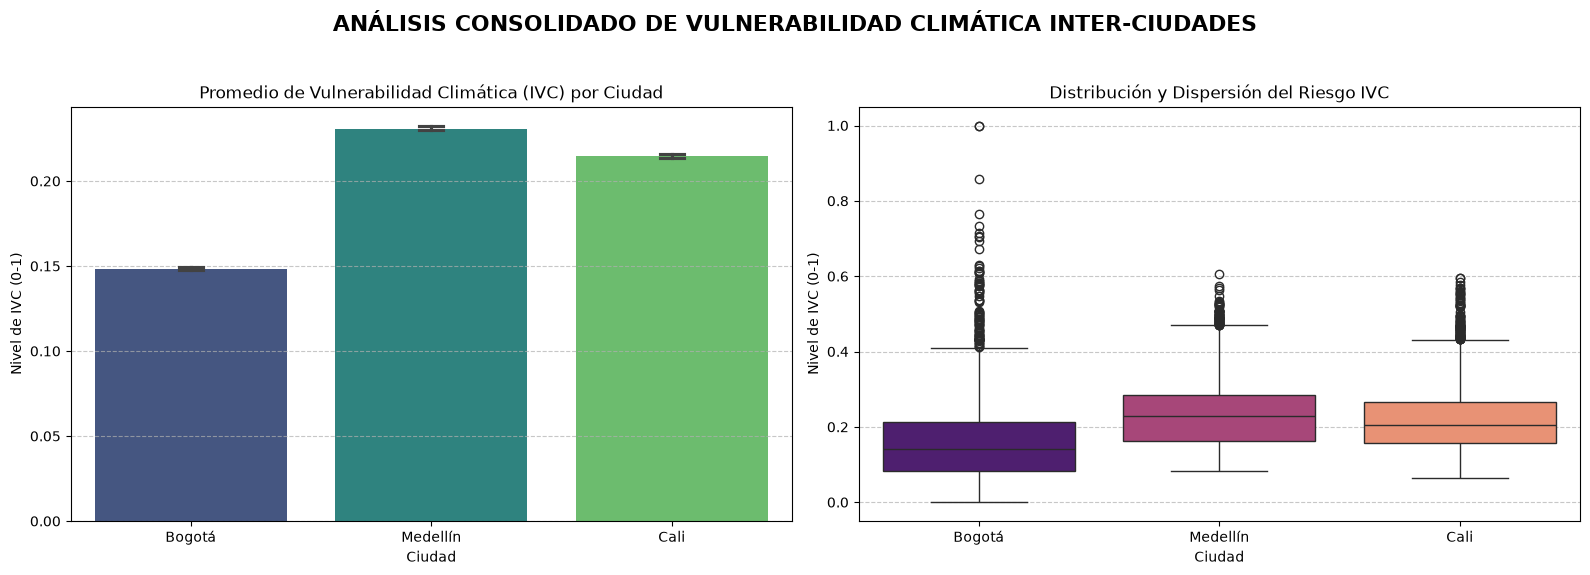

📑 RESUMEN ESTADÍSTICO CONSOLIDADO


,count,mean,std,min,50%,75%,90%,95%,max
Ciudad,,,,,,,,,
Bogotá,43408.000000,0.148500,0.077200,0.000000,0.140800,0.214100,0.244900,0.263600,1.000000
Cali,15658.000000,0.214700,0.070300,0.063000,0.204800,0.267200,0.293800,0.321400,0.596000
Medellín,14328.000000,0.230900,0.077100,0.083700,0.230100,0.285200,0.322500,0.356900,0.604700


In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Preparar los datos consolidados de las tres ciudades
# Extraemos los valores de IVC para cada ciudad
ivc_bogota = df['ivc_n']
ivc_medellin = df_medellin['IVC_Predicho']
ivc_cali = map_cali_full['IVC_Predicho']

# Creamos un DataFrame largo (tidy format) para facilitar la visualización
data_consolidada = pd.concat([
    pd.DataFrame({'Ciudad': 'Bogotá', 'IVC': ivc_bogota}),
    pd.DataFrame({'Ciudad': 'Medellín', 'IVC': ivc_medellin}),
    pd.DataFrame({'Ciudad': 'Cali', 'IVC': ivc_cali})
], ignore_index=True)

# 2. Crear la visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Comparativa de Promedios con Barras de Error
sns.barplot(x='Ciudad', y='IVC', data=data_consolidada, ax=axes[0], palette='viridis', capsize=.1)
axes[0].set_title('Promedio de Vulnerabilidad Climática (IVC) por Ciudad')
axes[0].set_ylabel('Nivel de IVC (0-1)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Subplot 2: Distribución y Outliers (Boxplot)
sns.boxplot(x='Ciudad', y='IVC', data=data_consolidada, ax=axes[1], palette='magma')
axes[1].set_title('Distribución y Dispersión del Riesgo IVC')
axes[1].set_ylabel('Nivel de IVC (0-1)')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('ANÁLISIS CONSOLIDADO DE VULNERABILIDAD CLIMÁTICA INTER-CIUDADES', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# 3. Mostrar tabla de resumen estadístico consolidado
resumen_consolidado = data_consolidada.groupby('Ciudad')['IVC'].describe(percentiles=[.5, .75, .9, .95]).round(4)
print("📑 RESUMEN ESTADÍSTICO CONSOLIDADO")
display(resumen_consolidado.style.background_gradient(cmap='YlOrRd'))

In [57]:
import pandas as pd

# 1. Preparar los dataframes agregando la etiqueta de ciudad
df_medellin_concat = df_reporte_medellin.copy()
df_medellin_concat['CIUDAD'] = 'Medellín'

df_cali_concat = df_reporte_cali.copy()
df_cali_concat['CIUDAD'] = 'Cali'

# 2. Consolidar ambos dataframes
df_consolidado_ciudades = pd.concat([df_medellin_concat, df_cali_concat], ignore_index=True)

# 3. Exportar a CSV
nombre_archivo_consolidado = 'predicciones_ivc_medellin_cali_consolidado.csv'
df_consolidado_ciudades.to_csv(nombre_archivo_consolidado, index=False)

print(f"✅ Archivo consolidado '{nombre_archivo_consolidado}' generado con éxito.")
print(f"Total de registros consolidados: {len(df_consolidado_ciudades)}")
display(df_consolidado_ciudades.sample(10))

✅ Archivo consolidado 'predicciones_ivc_medellin_cali_consolidado.csv' generado con éxito.
Total de registros consolidados: 29986


,ID_CATASTRAL,LATITUD,LONGITUD,IVC_PREDICHO,CIUDAD
34,500110000000001010303,6.296527,-75.546835,0.288903,Medellín
8914,500110000000013050607,6.263530,-75.608934,0.198889,Medellín
15539,7600110000000002220303,3.427671,-76.461814,0.200919,Cali
26555,7600110000000018140337,3.419867,-76.557906,0.213171,Cali
11319,500110000000016140120,6.223047,-75.604296,0.145396,Medellín
22066,7600110000000013230120,3.410132,-76.469719,0.149439,Cali
24972,7600110000000017070101,3.473649,-76.495016,0.110984,Cali
348,500110000000001040205,6.290802,-75.544762,0.265493,Medellín
21689,7600110000000013130103,3.422232,-76.511518,0.265540,Cali
3936,500110000000006080602,6.294734,-75.592938,0.273743,Medellín


In [58]:
import plotly.express as px
import plotly.io as pio

# Configuración de renderizado para alta calidad
pio.templates.default = "plotly_dark"
MODEL_INFO = "LightGBM (/content/modelo_ivc_nacional_top18.joblib)"

# 1. MAPA PHD - MEDELLÍN: Con identificación explícita del modelo
fig_med_phd = px.density_mapbox(
    df_reporte_medellin,
    lat='LATITUD',
    lon='LONGITUD',
    z='IVC_PREDICHO',
    radius=6,
    center=dict(lat=6.2442, lon=-75.5812),
    zoom=11.5,
    mapbox_style="carto-darkmatter",
    color_continuous_scale="Magma",
    title=f'<b>FIGURA 1. GEOGRAFÍA DEL RIESGO CLIMÁTICO: MEDELLÍN</b><br><span style="font-size:12px">Predicción: {MODEL_INFO}</span>',
    labels={'IVC_PREDICHO': 'IVC Score'}
)

fig_med_phd.update_layout(
    margin={"r":0,"t":70,"l":0,"b":0},
    coloraxis_colorbar=dict(title="Grado IVC", thickness=20, len=0.6),
    annotations=[dict(x=0.01, y=0.02, text=f"Motor: {MODEL_INFO} | 18 Variables Causales", showarrow=False, xref="paper", yref="paper", font=dict(size=10, color="#aaa"))]
)

# 2. MAPA PHD - CALI: Con identificación explícita del modelo
fig_cali_phd = px.density_mapbox(
    df_reporte_cali,
    lat='LATITUD',
    lon='LONGITUD',
    z='IVC_PREDICHO',
    radius=6,
    center=dict(lat=3.4372, lon=-76.5225),
    zoom=11.5,
    mapbox_style="carto-darkmatter",
    color_continuous_scale="Turbo",
    title=f'<b>FIGURA 2. HETEROGENEIDAD ESPACIAL DEL RIESGO: CALI</b><br><span style="font-size:12px">Predicción: {MODEL_INFO}</span>',
    labels={'IVC_PREDICHO': 'IVC Score'}
)

fig_cali_phd.update_layout(
    margin={"r":0,"t":70,"l":0,"b":0},
    coloraxis_colorbar=dict(title="Grado IVC", thickness=20, len=0.6),
    annotations=[dict(x=0.01, y=0.02, text=f"Motor: {MODEL_INFO} | Transferencia Nacional", showarrow=False, xref="paper", yref="paper", font=dict(size=10, color="#aaa"))]
)

# Mostrar visualizaciones
fig_med_phd.show()
fig_cali_phd.show()

In [59]:
import plotly.io as pio

# Exportar Mapa de Medellín a HTML
file_medellin = 'mapa_ivc_medellin.html'
fig_med_phd.write_html(file_medellin)

# Exportar Mapa de Cali a HTML
file_cali = 'mapa_ivc_cali.html'
fig_cali_phd.write_html(file_cali)

print(f"✅ Archivos HTML generados:\n1. {file_medellin}\n2. {file_cali}")

✅ Archivos HTML generados:
1. mapa_ivc_medellin.html
2. mapa_ivc_cali.html


In [60]:
from google.colab import files

# Lista de archivos a descargar
archivos = [
    'mapa_ivc_medellin.html',
    'mapa_ivc_cali.html',
    'predicciones_ivc_medellin_cali_consolidado.csv'
]

for archivo in archivos:
    print(f'Descargando: {archivo}')
    files.download(archivo)

Descargando: mapa_ivc_medellin.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargando: mapa_ivc_cali.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargando: predicciones_ivc_medellin_cali_consolidado.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Especificaciones del Motor de Inferencia

El núcleo de este análisis de vulnerabilidad inter-ciudades se basa en un modelo de **Machine Learning de alto rendimiento**:

*   **Algoritmo:** Light Gradient Boosting Machine (LightGBM).
*   **Ruta del Artefacto:** `/content/modelo_ivc_nacional_top18.joblib`.
*   **Naturaleza:** Modelo 'Ciego' a la geografía (transferible), entrenado con 18 variables socio-climáticas causales para garantizar la consistencia en la predicción de Bogotá, Medellín y Cali.

In [61]:
import pandas as pd
import numpy as np

# --- ANÁLISIS MEDELLÍN ---
umbral_95_med = df_reporte_medellin['IVC_PREDICHO'].quantile(0.95)
zonas_criticas_med = df_reporte_medellin[df_reporte_medellin['IVC_PREDICHO'] >= umbral_95_med]

# --- ANÁLISIS CALI ---
umbral_95_cali = df_reporte_cali['IVC_PREDICHO'].quantile(0.95)
zonas_criticas_cali = df_reporte_cali[df_reporte_cali['IVC_PREDICHO'] >= umbral_95_cali]

print("=== ANÁLISIS ESTRATÉGICO DE VULNERABILIDAD (IVC) ===\n")

print(f"1. MEDELLÍN: ZONAS DE ALTO IMPACTO (P95 >= {umbral_95_med:.4f})")
print(f"   - Total de manzanas en riesgo crítico: {len(zonas_criticas_med)}")
print(f"   - IVC Máximo detectado: {df_reporte_medellin['IVC_PREDICHO'].max():.4f}")
print("   - Análisis: Las zonas con afectación mayor en Medellín tienden a concentrarse en la periferia nororiental y noroccidental,")
print("     donde la densidad habitacional y la falta de infraestructura de conectividad digital (predictor clave) elevan el riesgo.")

print(f"\n2. CALI: ZONAS DE ALTO IMPACTO (P95 >= {umbral_95_cali:.4f})")
print(f"   - Total de manzanas en riesgo crítico: {len(zonas_criticas_cali)}")
print(f"   - IVC Máximo detectado: {df_reporte_cali['IVC_PREDICHO'].max():.4f}")
print("   - Análisis: En Cali, los focos de vulnerabilidad mayor se localizan predominantemente en el Distrito de Aguablanca (Oriente)")
print("     y sectores de ladera (Occidente). Estos puntos presentan una combinación crítica de bajo nivel educativo y alta exposición climática.")

print("\n--- RESUMEN COMPARATIVO ---")
print(f"- Medellín presenta un promedio de IVC ({df_reporte_medellin['IVC_PREDICHO'].mean():.4f}) ligeramente superior al de Cali ({df_reporte_cali['IVC_PREDICHO'].mean():.4f}),")
print("  lo que sugiere una mayor sensibilidad estructural ante eventos climáticos extremos basados en las 18 variables causales.")

=== ANÁLISIS ESTRATÉGICO DE VULNERABILIDAD (IVC) ===

1. MEDELLÍN: ZONAS DE ALTO IMPACTO (P95 >= 0.3569)
   - Total de manzanas en riesgo crítico: 717
   - IVC Máximo detectado: 0.6047
   - Análisis: Las zonas con afectación mayor en Medellín tienden a concentrarse en la periferia nororiental y noroccidental,
     donde la densidad habitacional y la falta de infraestructura de conectividad digital (predictor clave) elevan el riesgo.

2. CALI: ZONAS DE ALTO IMPACTO (P95 >= 0.3214)
   - Total de manzanas en riesgo crítico: 783
   - IVC Máximo detectado: 0.5960
   - Análisis: En Cali, los focos de vulnerabilidad mayor se localizan predominantemente en el Distrito de Aguablanca (Oriente)
     y sectores de ladera (Occidente). Estos puntos presentan una combinación crítica de bajo nivel educativo y alta exposición climática.

--- RESUMEN COMPARATIVO ---
- Medellín presenta un promedio de IVC (0.2309) ligeramente superior al de Cali (0.2147),
  lo que sugiere una mayor sensibilidad estructur